# Adult Income Prediction with ANNs — Controlled Deep-Learning Experiments

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, f1_score, roc_auc_score, roc_curve)
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import Markdown, display

SEED = 42
QUICK = False                      
EPOCHS       = 3 if QUICK else 50  
EPOCHS_SHORT = 3 if QUICK else 30   
EPOCHS_FINAL = 3 if QUICK else 80  
RED, CHARCOAL = '#CC0000', '#2C2C2C'

sns.set_theme(style='whitegrid')
keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__)

TensorFlow 2.20.0


In [2]:
import pandas as pd, numpy as np
df = pd.read_csv('adult.csv')
print('Shape:', df.shape)            
print('\nDtypes:\n', df.dtypes)
display(df.head())

for col in df.select_dtypes(exclude=np.number).columns:
    df[col] = df[col].str.strip()

Shape: (48842, 15)

Dtypes:
 age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
df.replace('?', np.nan, inplace=True)
missing = df.isnull().sum()
print(missing[missing > 0])

rows_before = len(df)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'\nDropped {rows_before - len(df):,} rows -> {len(df):,} clean records remain')

workclass         2799
occupation        2809
native-country     857
dtype: int64

Dropped 3,620 rows -> 45,222 clean records remain


In [4]:
df.drop(columns=['fnlwgt', 'education'], inplace=True)
print('Shape now:', df.shape)
print(df.columns.tolist())

Shape now: (45222, 13)
['age', 'workclass', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


income
0    34014
1    11208
Name: count, dtype: int64
income
0    0.752
1    0.248
Name: count, dtype: float64


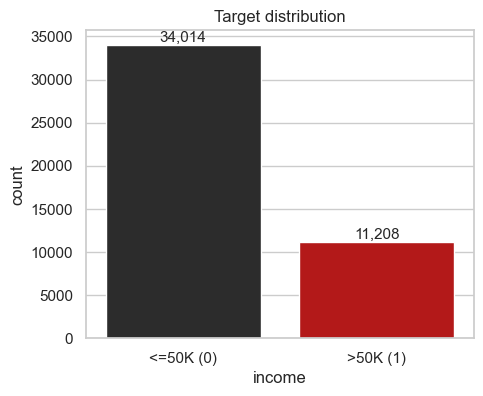

In [5]:
df['income'] = (df['income'] == '>50K').astype(int)
counts = df['income'].value_counts()
print(counts)
print((counts / len(df)).round(3))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x='income', data=df, palette=[CHARCOAL, RED])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=11)
ax.set_xticklabels(['<=50K (0)', '>50K (1)'])
ax.set_title('Target distribution')
plt.show()

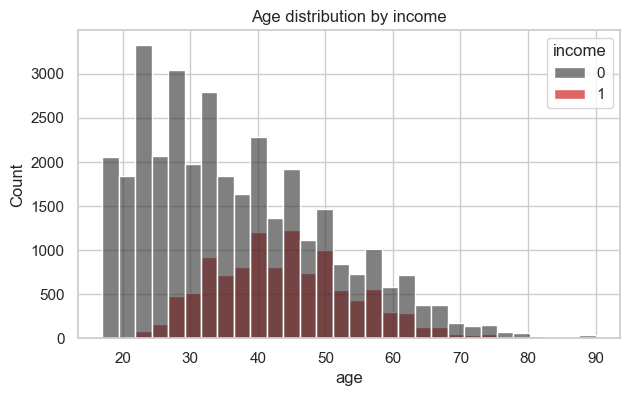

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='age', hue='income', bins=30, palette=[CHARCOAL, RED], multiple='layer', alpha=0.6)
plt.title('Age distribution by income'); plt.show()

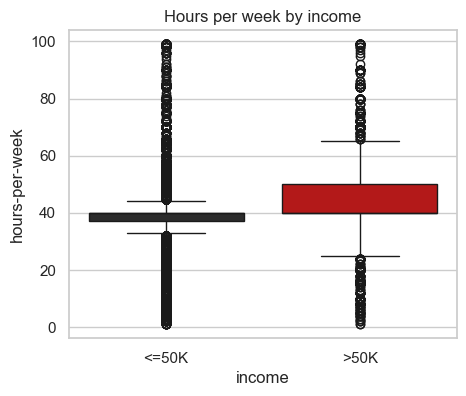

In [7]:
plt.figure(figsize=(5, 4))
sns.boxplot(data=df, x='income', y='hours-per-week', palette=[CHARCOAL, RED])
plt.xticks([0, 1], ['<=50K', '>50K']); plt.title('Hours per week by income'); plt.show()

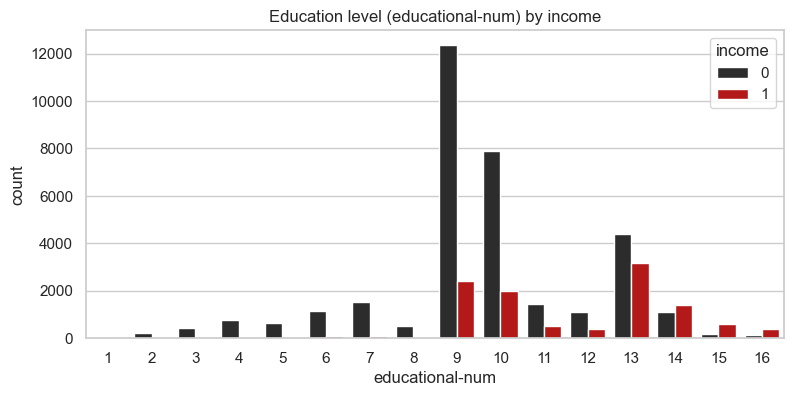

In [8]:
plt.figure(figsize=(9, 4))
sns.countplot(data=df, x='educational-num', hue='income', palette=[CHARCOAL, RED])
plt.title('Education level (educational-num) by income'); plt.show()

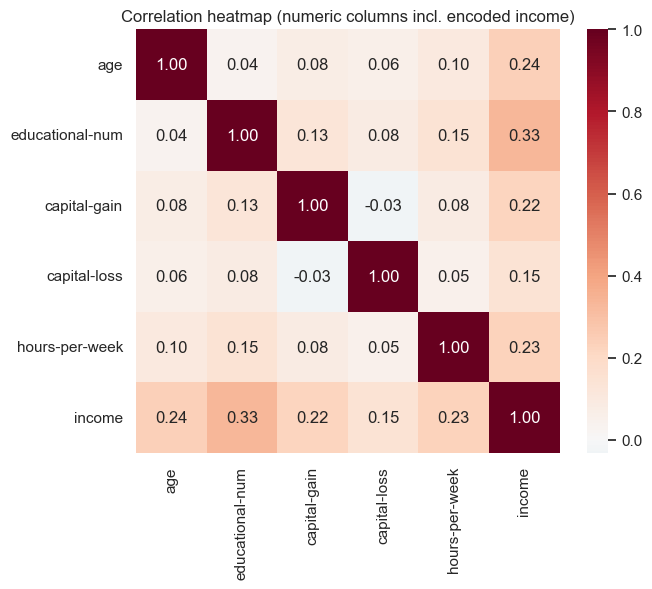

In [9]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Correlation heatmap (numeric columns incl. encoded income)'); plt.show()

In [10]:
X = df.drop('income', axis=1)
y = df['income']

X = pd.get_dummies(X, drop_first=True).astype('float32')     # one-hot encode categoricals
print('Columns after one-hot encoding:', X.shape[1])

num_cols = ['age', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()

# Scale numeric columns ONLY (not the 0/1 dummy columns); fit on train only -> no leakage
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])

print('X_train', X_train.shape, '| X_test', X_test.shape,
      '| y_train', y_train.shape, '| y_test', y_test.shape)
print('Class-1 ratio  full: %.3f | train: %.3f | test: %.3f' % (y.mean(), y_train.mean(), y_test.mean()))

# convert to numpy for Keras
feature_names = X_train.columns.tolist()
X_train = X_train.values.astype('float32'); X_test = X_test.values.astype('float32')
y_train = y_train.values.astype('int32');   y_test = y_test.values.astype('int32')
D = X_train.shape[1]

Columns after one-hot encoding: 80
X_train (36177, 80) | X_test (9045, 80) | y_train (36177,) | y_test (9045,)
Class-1 ratio  full: 0.248 | train: 0.248 | test: 0.248


In [11]:
def build_ann(input_dim, hidden_units=[128, 64], activation='relu', initializer='glorot_uniform',
              use_batch_norm=False, optimizer='adam', loss='binary_crossentropy'):
    """Returns a compiled keras.Sequential binary classifier.
    use_batch_norm=False : Dense(units, activation)
    use_batch_norm=True  : Dense(units) -> BatchNorm -> Activation   (canonical order)
    """
    keras.utils.set_random_seed(SEED)          # same seed for every experiment
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(input_dim,)))
    for units in hidden_units:
        if use_batch_norm:
            model.add(keras.layers.Dense(units, kernel_initializer=initializer))
            model.add(keras.layers.BatchNormalization())
            model.add(keras.layers.Activation(activation))
        else:
            model.add(keras.layers.Dense(units, activation=activation, kernel_initializer=initializer))
    model.add(keras.layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])
    return model


class ValF1(keras.callbacks.Callback):
    """Adds 'val_f1' (class 1) to the History at the end of every epoch."""
    def __init__(self, X_val, y_val):
        super().__init__(); self.X_val, self.y_val = X_val, y_val
    def on_epoch_end(self, epoch, logs=None):
        prob = self.model.predict(self.X_val, verbose=0).ravel()
        logs['val_f1'] = f1_score(self.y_val, (prob > 0.5).astype(int), zero_division=0)


def fit_model(model, epochs=None, verbose=0, class_weight=None):
    """model.fit(batch_size=64, validation_split=0.1) + per-epoch validation F1."""
    epochs = epochs or EPOCHS
    split_at = int(len(X_train) * (1 - 0.1))        # Keras takes the LAST 10% as validation
    cb = ValF1(X_train[split_at:], y_train[split_at:])
    return model.fit(X_train, y_train, epochs=epochs, batch_size=64, validation_split=0.1,
                     verbose=verbose, class_weight=class_weight, callbacks=[cb])


def evaluate(model):
    prob = model.predict(X_test, verbose=0).ravel()
    pred = (prob > 0.5).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average='binary', zero_division=0)
    return dict(acc=accuracy_score(y_test, pred), prec=p, rec=r, f1=f,
                auc=roc_auc_score(y_test, prob))


all_results, trained = {}, {}
def record(name, model, activation='relu', init='glorot_uniform', loss='BCE', bn=False, opt='adam'):
    """Evaluate on the test set and store the row for the Task-7 comparison table."""
    m = evaluate(model)
    all_results[name] = {'Model': name, 'Activation': activation, 'Init': init, 'Loss': loss,
                         'BatchNorm': bn, 'Optimizer': opt, 'Test Acc': m['acc'],
                         'Prec(1)': m['prec'], 'Recall(1)': m['rec'], 'F1(1)': m['f1'], 'ROC-AUC': m['auc']}
    trained[name] = model
    return all_results[name]


def first_cross(values, thr):
    """0-based index of first epoch where values >= thr (None if never)."""
    idx = np.where(np.array(values) >= thr)[0]
    return int(idx[0]) if len(idx) else None

In [12]:
model_base = build_ann(input_dim=D)
model_base.summary()

manual = (D * 128 + 128) + (128 * 64 + 64) + (64 * 1 + 1)
print(f'\nManual parameter count: ({D}x128+128) + (128x64+64) + (64x1+1) = {manual:,}')
print(f'Keras count_params()  : {model_base.count_params():,}  ->  match: {manual == model_base.count_params()}')
print('Loss used by baseline :', model_base.loss)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)


Manual parameter count: (80x128+128) + (128x64+64) + (64x1+1) = 18,689
Keras count_params()  : 18,689  ->  match: True
Loss used by baseline : binary_crossentropy


In [13]:
history_base = fit_model(model_base, epochs=EPOCHS, verbose=1)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 889us/step - accuracy: 0.8161 - loss: 0.3855 - val_accuracy: 0.8485 - val_loss: 0.3210 - val_f1: 0.6646
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 552us/step - accuracy: 0.8517 - loss: 0.3151 - val_accuracy: 0.8477 - val_loss: 0.3205 - val_f1: 0.6601
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 584us/step - accuracy: 0.8544 - loss: 0.3107 - val_accuracy: 0.8491 - val_loss: 0.3198 - val_f1: 0.6609
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 612us/step - accuracy: 0.8566 - loss: 0.3076 - val_accuracy: 0.8483 - val_loss: 0.3192 - val_f1: 0.6592
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 598us/step - accuracy: 0.8577 - loss: 0.3050 - val_accuracy: 0.8496 - val_loss: 0.3192 - val_f1: 0.6634
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 580us/step - accuracy: 0.8593 - loss: 0.3024 - val_accuracy: 0.8494 - val_loss: 0.3190 - val_f1: 0.6621
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 609us/step - accuracy: 0.8606 - loss: 0.2999 - val_accuracy: 0.8491 - val_l

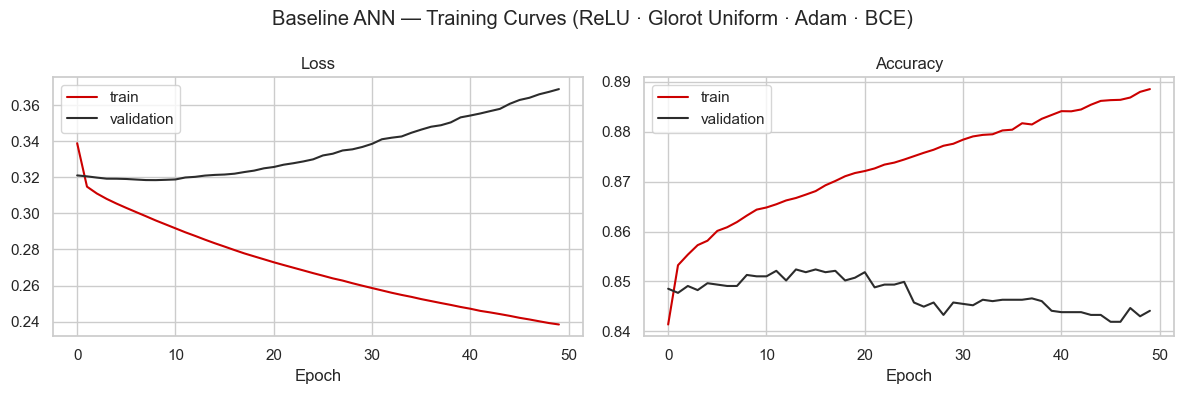

In [14]:
def plot_curves(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['loss'], color=RED, label='train'); ax[0].plot(h.history['val_loss'], color=CHARCOAL, label='validation')
    ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(h.history['accuracy'], color=RED, label='train'); ax[1].plot(h.history['val_accuracy'], color=CHARCOAL, label='validation')
    ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_curves(history_base, 'Baseline ANN — Training Curves (ReLU · Glorot Uniform · Adam · BCE)')

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 227us/step
              precision    recall  f1-score   support

       <=50K       0.87      0.92      0.89      6803
        >50K       0.70      0.59      0.64      2242

    accuracy                           0.84      9045
   macro avg       0.79      0.75      0.77      9045
weighted avg       0.83      0.84      0.83      9045



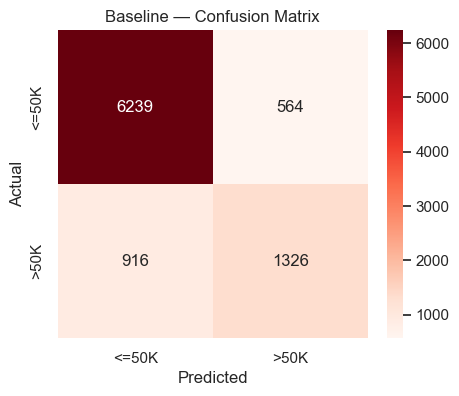

**Baseline, class 1 (>50K):** Precision = **0.702**, Recall = **0.591**, F1 = **0.642** (overall accuracy 0.836). For the minority class, Recall tells us how many true high-earners we find and Precision how many of our `>50K` predictions are right — these matter more than accuracy, which is inflated by the majority class. These numbers are stored in `all_results` for the Task 7 table.

In [15]:
y_pred_prob = model_base.predict(X_test).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Baseline — Confusion Matrix'); plt.show()

row = record('Baseline', model_base)
display(Markdown(
    f"**Baseline, class 1 (>50K):** Precision = **{row['Prec(1)']:.3f}**, Recall = **{row['Recall(1)']:.3f}**, "
    f"F1 = **{row['F1(1)']:.3f}** (overall accuracy {row['Test Acc']:.3f}). "
    "For the minority class, Recall tells us how many true high-earners we find and Precision how many of our "
    "`>50K` predictions are right — these matter more than accuracy, which is inflated by the majority class. "
    "These numbers are stored in `all_results` for the Task 7 table."))

In [16]:
acts = ['relu', 'tanh', 'sigmoid', 'elu']
models_act, hist_act = {}, {}
for a in acts:
    print('Training activation =', a)
    m = build_ann(input_dim=D, activation=a)
    hist_act[a] = fit_model(m, epochs=EPOCHS)
    models_act[a] = m
    record(f'Act: {a}', m, activation=a)

history_relu, history_tanh = hist_act['relu'], hist_act['tanh']
history_sigmoid, history_elu = hist_act['sigmoid'], hist_act['elu']
pd.DataFrame([all_results[f'Act: {a}'] for a in acts])[['Model','Test Acc','Prec(1)','Recall(1)','F1(1)','ROC-AUC']]

Training activation = relu
Training activation = tanh
Training activation = sigmoid
Training activation = elu


,Model,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Act: relu,0.836374,0.701587,0.591436,0.641820,0.887280
1,Act: tanh,0.845882,0.730937,0.598573,0.658166,0.903453
2,Act: sigmoid,0.853068,0.750137,0.610616,0.673224,0.911942
3,Act: elu,0.850304,0.733930,0.621320,0.672947,0.905519


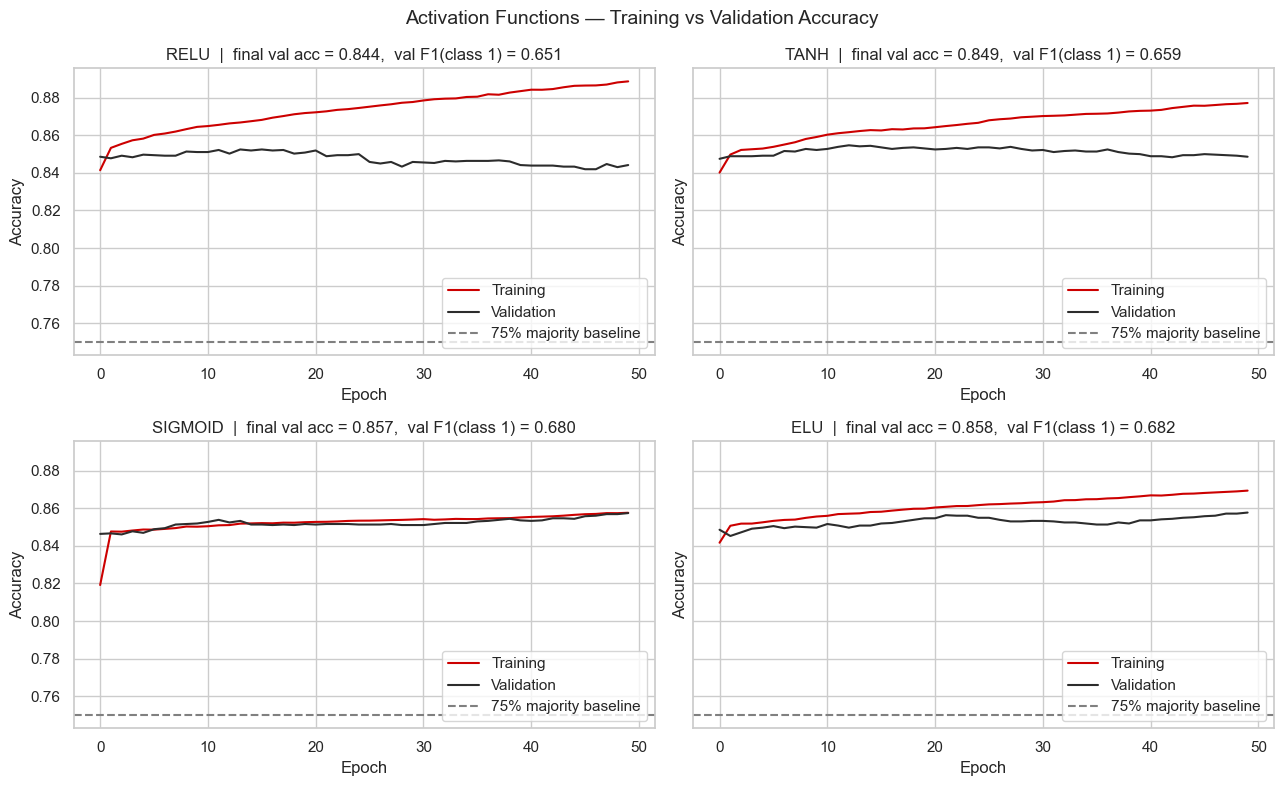

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, a in zip(axes.ravel(), acts):
    h = hist_act[a].history
    ax.plot(h['accuracy'], color=RED, label='Training')
    ax.plot(h['val_accuracy'], color=CHARCOAL, label='Validation')
    ax.axhline(0.75, color='gray', ls='--', label='75% majority baseline')
    ax.set_title(f"{a.upper()}  |  final val acc = {h['val_accuracy'][-1]:.3f},  val F1(class 1) = {h['val_f1'][-1]:.3f}")
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.legend(loc='lower right')
fig.suptitle('Activation Functions — Training vs Validation Accuracy', fontsize=14)
plt.tight_layout(); plt.show()

dead_fraction (activation == 0, over all neurons x samples): 0.616
Neurons that are 0 for ALL 500 samples: 0 / 128


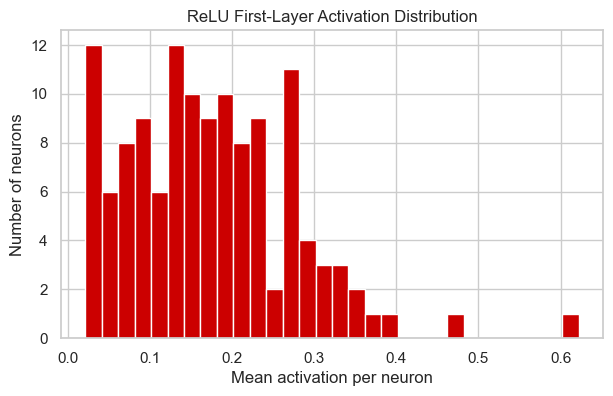

**dead_fraction = 0.616** (0 of 128 neurons never fire on these 500 samples).

In [18]:
model_relu = models_act['relu']
intermediate = keras.Model(inputs=model_relu.inputs, outputs=model_relu.layers[0].output)
activations = intermediate.predict(X_test[:500], verbose=0)

dead_fraction = np.mean(activations == 0)
always_dead = int(np.sum(np.all(activations == 0, axis=0)))
print(f'dead_fraction (activation == 0, over all neurons x samples): {dead_fraction:.3f}')
print(f'Neurons that are 0 for ALL 500 samples: {always_dead} / {activations.shape[1]}')

plt.figure(figsize=(7, 4))
plt.hist(activations.mean(axis=0), bins=30, color=RED, edgecolor='white')
plt.xlabel('Mean activation per neuron'); plt.ylabel('Number of neurons')
plt.title('ReLU First-Layer Activation Distribution'); plt.show()

display(Markdown(f"**dead_fraction = {dead_fraction:.3f}** ({always_dead} of {activations.shape[1]} neurons never fire on these 500 samples)."))

Layer 1: mean |gradient| = 9.10e-05
Layer 2: mean |gradient| = 2.13e-04
Output: mean |gradient| = 7.53e-03


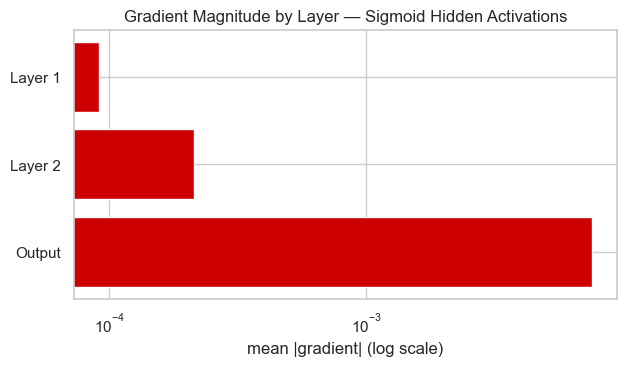

Output-layer gradient is **82.8x** the Layer-1 gradient (vanishing gradients are visible).

In [19]:
m = models_act['sigmoid']
xb = tf.constant(X_train[:512])
yb = tf.constant(y_train[:512].astype('float32').reshape(-1, 1))

with tf.GradientTape() as tape:
    pred = m(xb, training=True)
    loss = tf.reduce_mean(keras.losses.binary_crossentropy(yb, pred))
grads = tape.gradient(loss, m.trainable_variables)

kernel_grads = [g for v, g in zip(m.trainable_variables, grads) if len(v.shape) == 2]   # weights only
layer_names = ['Layer 1', 'Layer 2', 'Output']
mean_abs = [float(tf.reduce_mean(tf.abs(g))) for g in kernel_grads]
for n, g in zip(layer_names, mean_abs): print(f'{n}: mean |gradient| = {g:.2e}')

plt.figure(figsize=(7, 3.5))
plt.barh(layer_names[::-1], mean_abs[::-1], color=RED)
plt.xscale('log'); plt.xlabel('mean |gradient| (log scale)')
plt.title('Gradient Magnitude by Layer — Sigmoid Hidden Activations'); plt.show()

ratio = mean_abs[-1] / mean_abs[0]
display(Markdown(f"Output-layer gradient is **{ratio:.1f}x** the Layer-1 gradient "
                 f"({'vanishing gradients are visible' if ratio > 10 else 'only a mild vanishing effect in this shallow 2-hidden-layer net'})."))

In [20]:
info = { 
 'relu':    ('max(0, x)',                    '[0, ∞)',  'No',  'Low',      'High'),
 'tanh':    ('(eˣ − e⁻ˣ)/(eˣ + e⁻ˣ)',        '(−1, 1)', 'Yes', 'Medium',   'Low'),
 'sigmoid': ('1/(1 + e⁻ˣ)',                  '(0, 1)',  'No',  'High',     'Low'),
 'elu':     ('x if x>0 else α(eˣ − 1)',      '(−α, ∞)', 'Roughly', 'Low',   'Very low'),
}
names = {'relu': 'ReLU', 'tanh': 'Tanh', 'sigmoid': 'Sigmoid (hidden)', 'elu': 'ELU'}
lines = ['| Activation | Formula | Output Range | Zero-Centred | Vanishing Gradient Risk | Dead Neuron Risk | Val Accuracy on Adult (this run) |',
         '|---|---|---|---|---|---|---|']
for a in acts:
    f, rng, zc, vg, dn = info[a]
    lines.append(f"| {names[a]} | {f} | {rng} | {zc} | {vg} | {dn} | {hist_act[a].history['val_accuracy'][-1]:.4f} |")
lines.append("| Sigmoid (output layer only) | 1/(1 + e⁻ˣ) | (0, 1) | No | n/a (last layer) | n/a | n/a — always correct for binary output |")
best_act = max(acts, key=lambda a: all_results[f'Act: {a}']['F1(1)'])
display(Markdown('\n'.join(lines)))
display(Markdown(
 "**Note:** sigmoid in the *output* layer is always correct for binary classification, regardless of the hidden activation — it turns the logit into a probability.\n\n"
 f"**Recommendation:** in this run **{names[best_act]}** achieved the best test F1 for class 1 "
 f"({all_results['Act: '+best_act]['F1(1)']:.3f}). Because ReLU/ELU have non-saturating gradients, are cheap, and avoid the vanishing-gradient problem that hurts sigmoid/tanh, "
 "a ReLU-family activation is the sensible default for this tabular network; choose ELU if dead neurons look problematic, and use the best F1 above as the tie-breaker."))

| Activation | Formula | Output Range | Zero-Centred | Vanishing Gradient Risk | Dead Neuron Risk | Val Accuracy on Adult (this run) |
|---|---|---|---|---|---|---|
| ReLU | max(0, x) | [0, ∞) | No | Low | High | 0.8441 |
| Tanh | (eˣ − e⁻ˣ)/(eˣ + e⁻ˣ) | (−1, 1) | Yes | Medium | Low | 0.8485 |
| Sigmoid (hidden) | 1/(1 + e⁻ˣ) | (0, 1) | No | High | Low | 0.8574 |
| ELU | x if x>0 else α(eˣ − 1) | (−α, ∞) | Roughly | Low | Very low | 0.8577 |
| Sigmoid (output layer only) | 1/(1 + e⁻ˣ) | (0, 1) | No | n/a (last layer) | n/a | n/a — always correct for binary output |

**Note:** sigmoid in the *output* layer is always correct for binary classification, regardless of the hidden activation — it turns the logit into a probability.

**Recommendation:** in this run **Sigmoid (hidden)** achieved the best test F1 for class 1 (0.673). Because ReLU/ELU have non-saturating gradients, are cheap, and avoid the vanishing-gradient problem that hurts sigmoid/tanh, a ReLU-family activation is the sensible default for this tabular network; choose ELU if dead neurons look problematic, and use the best F1 above as the tie-breaker.

In [21]:
inits = ['glorot_uniform', 'glorot_normal', 'he_uniform', 'he_normal', 'zeros']
models_init, hist_init, init_weights = {}, {}, {}
for ini in inits:
    m = build_ann(input_dim=D, activation='relu', initializer=ini)
    init_weights[ini] = m.layers[0].get_weights()[0].copy()      
    print('Training initializer =', ini)
    hist_init[ini] = fit_model(m, epochs=EPOCHS)
    models_init[ini] = m
    record(f'Init: {ini}', m, init=ini)
pd.DataFrame([all_results[f'Init: {i}'] for i in inits])[['Model','Test Acc','Prec(1)','Recall(1)','F1(1)','ROC-AUC']]

Training initializer = glorot_uniform
Training initializer = glorot_normal
Training initializer = he_uniform
Training initializer = he_normal
Training initializer = zeros


,Model,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Init: glorot_uniform,0.836374,0.701587,0.591436,0.641820,0.887280
1,Init: glorot_normal,0.833610,0.698225,0.578947,0.633016,0.882420
2,Init: he_uniform,0.829961,0.680884,0.590990,0.632760,0.882068
3,Init: he_normal,0.832615,0.705186,0.557984,0.623008,0.881670
4,Init: zeros,0.752128,0.000000,0.000000,0.000000,0.500223


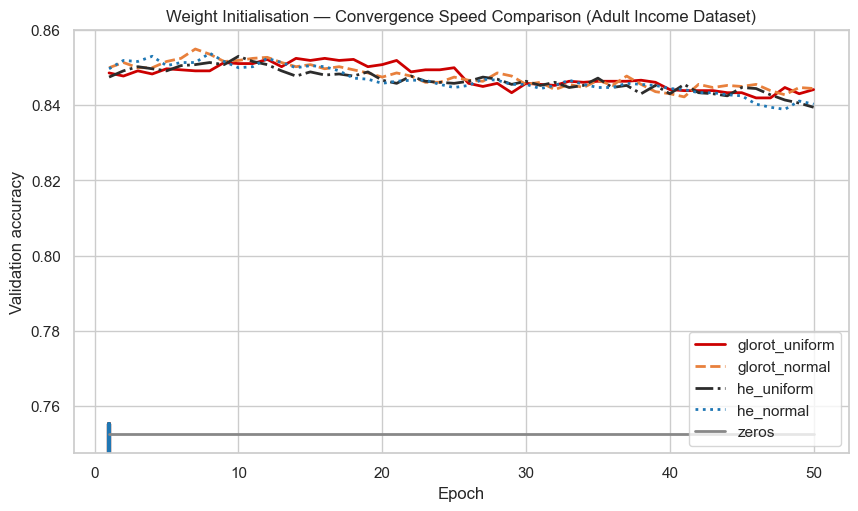

glorot_uniform  first epoch >= 82% val acc: 1
glorot_normal   first epoch >= 82% val acc: 1
he_uniform      first epoch >= 82% val acc: 1
he_normal       first epoch >= 82% val acc: 1
zeros           first epoch >= 82% val acc: never


In [22]:
colors = dict(zip(inits, [RED, '#E8803C', CHARCOAL, '#1F77B4', '#888888']))
styles = dict(zip(inits, ['-', '--', '-.', ':', '-']))
plt.figure(figsize=(10, 5.5))
for ini in inits:
    va = hist_init[ini].history['val_accuracy']
    ep = np.arange(1, len(va) + 1)
    plt.plot(ep, va, color=colors[ini], ls=styles[ini], lw=2, label=ini)
    if ini != 'zeros':
        e = first_cross(va, 0.82)
        if e is not None:
            plt.axvline(e + 1, ymin=0, ymax=0.07, color=colors[ini], lw=3)   
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy'); plt.legend(loc='lower right')
plt.title('Weight Initialisation — Convergence Speed Comparison (Adult Income Dataset)')
plt.show()
for ini in inits:
    e = first_cross(hist_init[ini].history['val_accuracy'], 0.82)
    print(f'{ini:15s} first epoch >= 82% val acc:', 'never' if e is None else e + 1)

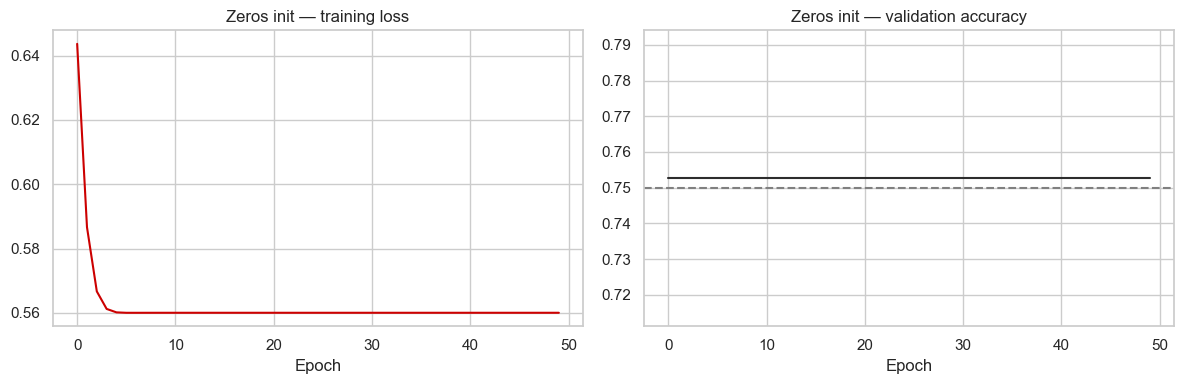

Test metrics (zeros): {'acc': 0.752, 'prec': 0.0, 'rec': 0.0, 'f1': 0.0, 'auc': 0.5}


In [23]:
hz = hist_init['zeros'].history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hz['loss'], color=RED); ax[0].set_title('Zeros init — training loss'); ax[0].set_xlabel('Epoch')
ax[1].plot(hz['val_accuracy'], color=CHARCOAL); ax[1].axhline(0.75, color='gray', ls='--')
ax[1].set_title('Zeros init — validation accuracy'); ax[1].set_xlabel('Epoch')
plt.tight_layout(); plt.show()
print('Test metrics (zeros):', {k: round(v, 3) for k, v in evaluate(models_init['zeros']).items()})

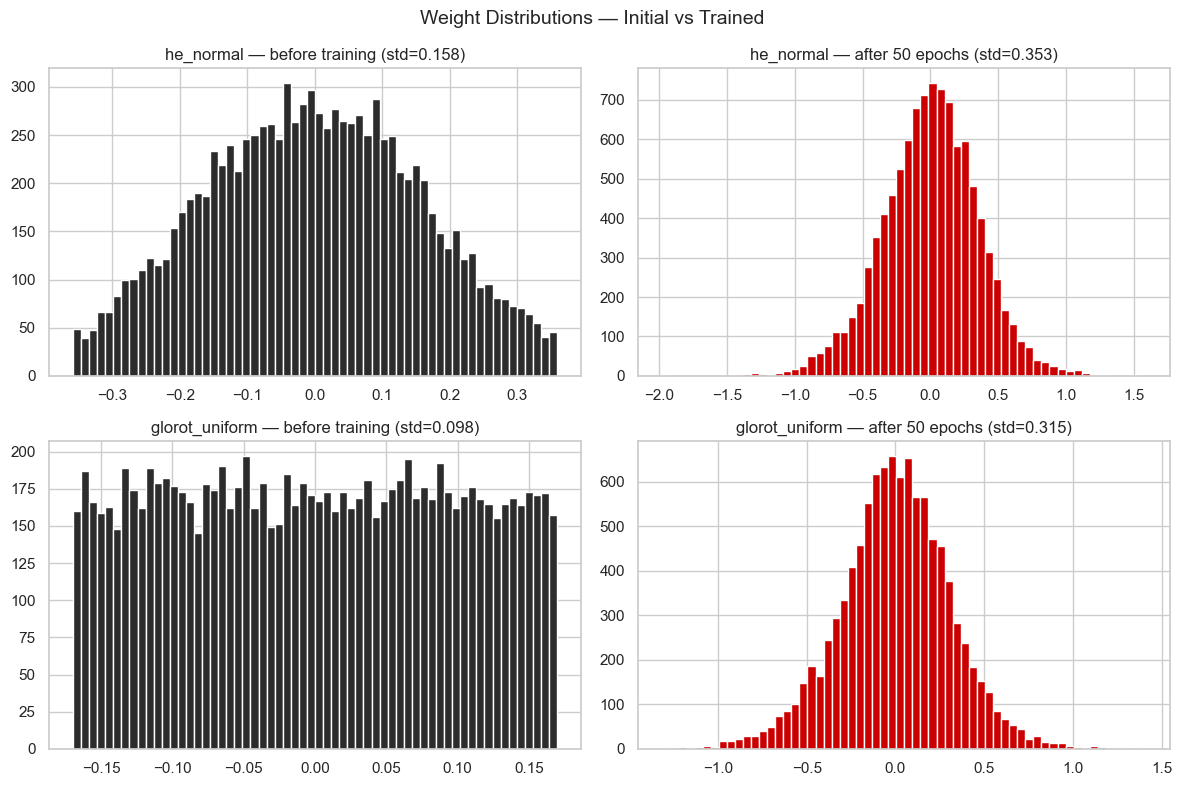

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for r, ini in enumerate(['he_normal', 'glorot_uniform']):
    before = init_weights[ini].ravel()
    after  = models_init[ini].layers[0].get_weights()[0].ravel()
    axes[r, 0].hist(before, bins=60, color=CHARCOAL); axes[r, 0].set_title(f'{ini} — before training (std={before.std():.3f})')
    axes[r, 1].hist(after,  bins=60, color=RED);      axes[r, 1].set_title(f'{ini} — after {EPOCHS} epochs (std={after.std():.3f})')
fig.suptitle('Weight Distributions — Initial vs Trained', fontsize=14)
plt.tight_layout(); plt.show()

In [25]:
assert model_base.loss == 'binary_crossentropy', model_base.loss
print('Baseline loss confirmed:', model_base.loss)

Baseline loss confirmed: binary_crossentropy


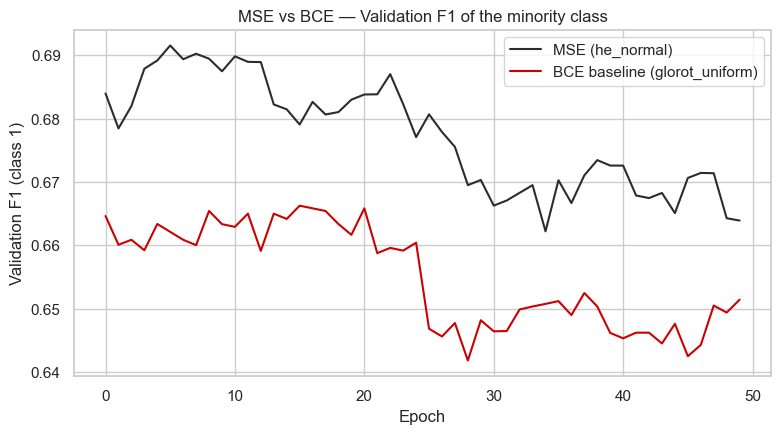

{'Test Acc': 0.838, 'Prec(1)': 0.688, 'Recall(1)': 0.631, 'F1(1)': 0.658, 'ROC-AUC': 0.892}


In [26]:
model_mse = build_ann(input_dim=D, loss='mean_squared_error', activation='relu', initializer='he_normal')
history_mse = fit_model(model_mse, epochs=EPOCHS)
record('MSE', model_mse, init='he_normal', loss='MSE')

plt.figure(figsize=(9, 4.5))
plt.plot(history_mse.history['val_f1'], color=CHARCOAL, label='MSE (he_normal)')
plt.plot(history_base.history['val_f1'], color=RED, label='BCE baseline (glorot_uniform)')
plt.xlabel('Epoch'); plt.ylabel('Validation F1 (class 1)'); plt.legend()
plt.title('MSE vs BCE — Validation F1 of the minority class'); plt.show()
print({k: round(v, 3) for k, v in all_results['MSE'].items() if k in ['Test Acc','Prec(1)','Recall(1)','F1(1)','ROC-AUC']})

class_weight_dict = {0: 0.665, 1: 2.017}


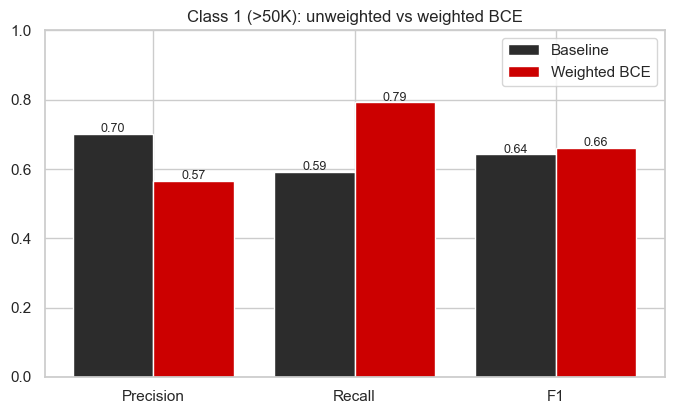

In [27]:
weights = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)
class_weight_dict = {0: weights[0], 1: weights[1]}
print('class_weight_dict =', {k: round(v, 3) for k, v in class_weight_dict.items()})

model_wbce = build_ann(input_dim=D, loss='binary_crossentropy', activation='relu', initializer='he_normal')
history_wbce = fit_model(model_wbce, epochs=EPOCHS, class_weight=class_weight_dict)
record('Weighted BCE', model_wbce, init='he_normal', loss='Weighted BCE')

def compare_bars(names, title):
    metrics = ['Prec(1)', 'Recall(1)', 'F1(1)']
    x = np.arange(len(metrics)); w = 0.8 / len(names)
    cols = [CHARCOAL, RED, '#E8803C', '#1F77B4']
    plt.figure(figsize=(8, 4.5))
    for i, n in enumerate(names):
        vals = [all_results[n][m] for m in metrics]
        bars = plt.bar(x + i * w - 0.4 + w / 2, vals, w, label=n, color=cols[i])
        for b, v in zip(bars, vals): plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f'{v:.2f}', ha='center', fontsize=9)
    plt.xticks(x, ['Precision', 'Recall', 'F1']); plt.ylim(0, 1); plt.legend(); plt.title(title); plt.show()

compare_bars(['Baseline', 'Weighted BCE'], 'Class 1 (>50K): unweighted vs weighted BCE')

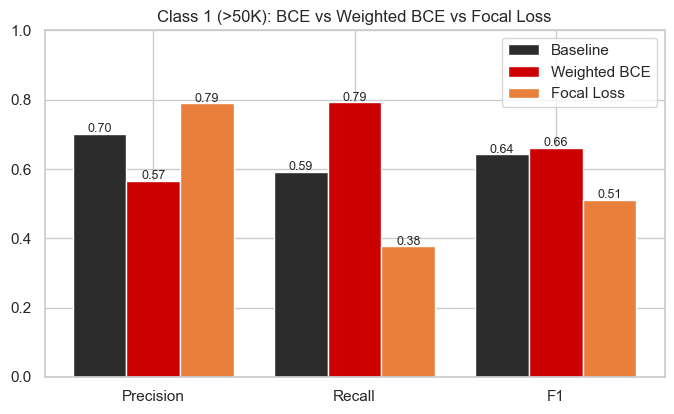

,Model,Prec(1),Recall(1),F1(1)
0,Baseline,0.701587,0.591436,0.641820
1,Weighted BCE,0.566369,0.791704,0.660342
2,Focal Loss,0.789720,0.376896,0.510266


In [28]:
def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, tf.shape(y_pred)), y_pred.dtype)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        bce = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)
        weight = alpha * y_true * (1 - y_pred) ** gamma + (1 - alpha) * (1 - y_true) * y_pred ** gamma
        return tf.reduce_mean(weight * bce)
    return loss

model_focal = build_ann(input_dim=D, loss=focal_loss(gamma=2.0, alpha=0.25), activation='relu', initializer='he_normal')
history_focal = fit_model(model_focal, epochs=EPOCHS)
record('Focal Loss', model_focal, init='he_normal', loss='Focal')

compare_bars(['Baseline', 'Weighted BCE', 'Focal Loss'], 'Class 1 (>50K): BCE vs Weighted BCE vs Focal Loss')
display(pd.DataFrame([all_results[n] for n in ['Baseline', 'Weighted BCE', 'Focal Loss']])[['Model','Prec(1)','Recall(1)','F1(1)']])

In [29]:
def f1_of(n): return all_results[n]['F1(1)']
tbl = ['| Loss Function | Formula (simplified) | Best For | Imbalance Handling | Class-1 F1 on Adult (this run) |', '|---|---|---|---|---|',
 f"| BCE | −[y·log p + (1−y)·log(1−p)] | Balanced binary classification | None | {f1_of('Baseline'):.3f} |",
 f"| Weighted BCE | −[w₁·y·log p + w₀·(1−y)·log(1−p)] | Moderately imbalanced binary data | Class weights (explicit) | {f1_of('Weighted BCE'):.3f} |",
 f"| MSE (classification) | (y − p)² | Regression — *not* recommended here | None (weak gradients when saturated) | {f1_of('MSE'):.3f} |",
 f"| Focal Loss | −α·(1−p)^γ·y·log p − (1−α)·p^γ·(1−y)·log(1−p) | Extreme imbalance / many easy negatives | Down-weights easy examples | {f1_of('Focal Loss'):.3f} |"]
best_loss = max(['Baseline', 'Weighted BCE', 'Focal Loss', 'MSE'], key=f1_of)
tbl.append(f"| **Recommendation** | **{best_loss}** | Highest class-1 F1 in this run | | **{f1_of(best_loss):.3f}** |")
display(Markdown('\n'.join(tbl)))
display(Markdown(
 f"**Production recommendation:** use **{best_loss}** for the Adult Income ANN. BCE-family losses are the statistically correct choice for a sigmoid output "
 "(MSE is not). With a ~3:1 imbalance, **weighted BCE** is the simplest, most stable and most interpretable way to raise minority-class Recall "
 "(one hyper-parameter-free class-weight vector), while focal loss adds two extra hyper-parameters (γ, α) to tune. Pick the option with the best F1 / recall trade-off for the business cost of missing high earners."))

| Loss Function | Formula (simplified) | Best For | Imbalance Handling | Class-1 F1 on Adult (this run) |
|---|---|---|---|---|
| BCE | −[y·log p + (1−y)·log(1−p)] | Balanced binary classification | None | 0.642 |
| Weighted BCE | −[w₁·y·log p + w₀·(1−y)·log(1−p)] | Moderately imbalanced binary data | Class weights (explicit) | 0.660 |
| MSE (classification) | (y − p)² | Regression — *not* recommended here | None (weak gradients when saturated) | 0.658 |
| Focal Loss | −α·(1−p)^γ·y·log p − (1−α)·p^γ·(1−y)·log(1−p) | Extreme imbalance / many easy negatives | Down-weights easy examples | 0.510 |
| **Recommendation** | **Weighted BCE** | Highest class-1 F1 in this run | | **0.660** |

**Production recommendation:** use **Weighted BCE** for the Adult Income ANN. BCE-family losses are the statistically correct choice for a sigmoid output (MSE is not). With a ~3:1 imbalance, **weighted BCE** is the simplest, most stable and most interpretable way to raise minority-class Recall (one hyper-parameter-free class-weight vector), while focal loss adds two extra hyper-parameters (γ, α) to tune. Pick the option with the best F1 / recall trade-off for the business cost of missing high earners.

In [30]:
keras.utils.set_random_seed(SEED)
model_bn = keras.Sequential([
    keras.layers.Dense(128, kernel_initializer='he_normal', input_shape=(X_train.shape[1],)),
    keras.layers.BatchNormalization(), keras.layers.Activation('relu'),
    keras.layers.Dense(64, kernel_initializer='he_normal'),
    keras.layers.BatchNormalization(), keras.layers.Activation('relu'),
    keras.layers.Dense(1, activation='sigmoid')])           # canonical: Dense -> BN -> Activation
model_bn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_bn.summary()
print('\nBN params: layer1 = 4x128 =', 4*128, '| layer2 = 4x64 =', 4*64,
      '-> trainable (gamma, beta) =', 2*128 + 2*64, '| non-trainable (moving mean/var) =', 2*128 + 2*64)

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_39 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)


BN params: layer1 = 4x128 = 512 | layer2 = 4x64 = 256 -> trainable (gamma, beta) = 384 | non-trainable (moving mean/var) = 384


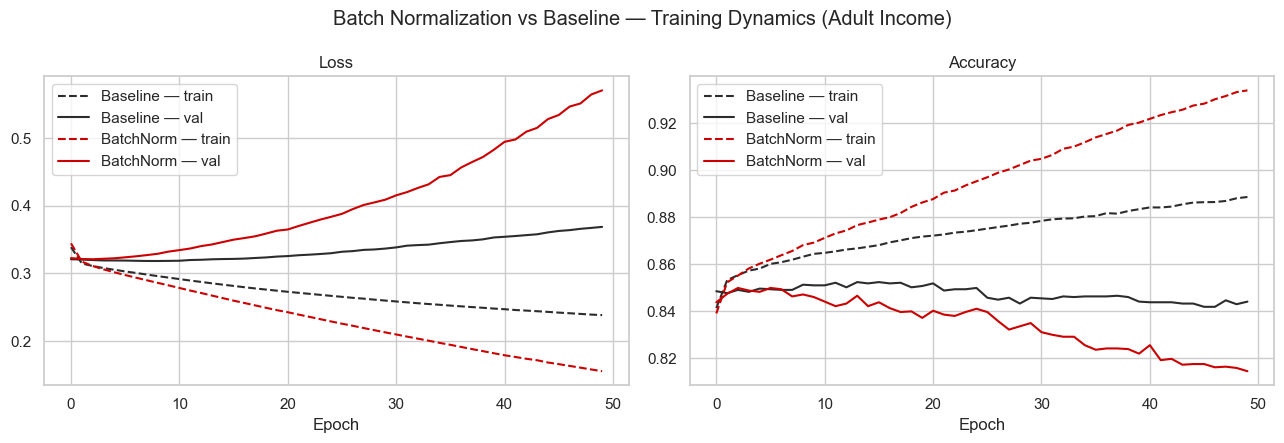

Baseline   train-val acc gap = +0.0445 | test Acc = 0.8364 | test F1(1) = 0.6418
BatchNorm  train-val acc gap = +0.1193 | test Acc = 0.8136 | test F1(1) = 0.5779


In [31]:
history_bn = fit_model(model_bn, epochs=EPOCHS)
record('BatchNorm', model_bn, init='he_normal', bn=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for key, a, t in [('loss', ax[0], 'Loss'), ('accuracy', ax[1], 'Accuracy')]:
    a.plot(history_base.history[key], color=CHARCOAL, ls='--', label='Baseline — train')
    a.plot(history_base.history['val_' + key], color=CHARCOAL, label='Baseline — val')
    a.plot(history_bn.history[key], color=RED, ls='--', label='BatchNorm — train')
    a.plot(history_bn.history['val_' + key], color=RED, label='BatchNorm — val')
    a.set_title(t); a.set_xlabel('Epoch'); a.legend()
fig.suptitle('Batch Normalization vs Baseline — Training Dynamics (Adult Income)')
plt.tight_layout(); plt.show()

for n, h in [('Baseline', history_base), ('BatchNorm', history_bn)]:
    gap = h.history['accuracy'][-1] - h.history['val_accuracy'][-1]
    r = all_results[n]
    print(f"{n:10s} train-val acc gap = {gap:+.4f} | test Acc = {r['Test Acc']:.4f} | test F1(1) = {r['F1(1)']:.4f}")

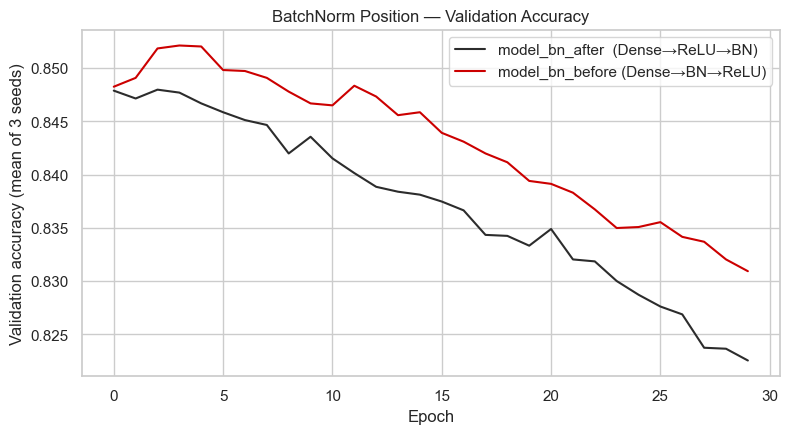

Test F1(1) before-activation: 0.6570 ± 0.0255
Test F1(1) after-activation : 0.6361 ± 0.0147


**Better on Adult Income (mean test F1): BN before activation.** Welch t-test over 3 seeds: t = 1.00, p = 0.385 → difference is **NOT statistically meaningful** at α = 0.05 (note: with only a few seeds the test has low power).

In [32]:
SEEDS = [0, 1] if QUICK else [0, 1, 2]

def build_bn_order(order, seed):
    keras.utils.set_random_seed(seed)
    layers = [keras.layers.Input(shape=(D,))]
    for units in [128, 64]:
        layers.append(keras.layers.Dense(units, kernel_initializer='he_normal'))
        if order == 'before':   layers += [keras.layers.BatchNormalization(), keras.layers.Activation('relu')]   # (b) canonical
        else:                   layers += [keras.layers.Activation('relu'), keras.layers.BatchNormalization()]   # (a) after
    layers.append(keras.layers.Dense(1, activation='sigmoid'))
    m = keras.Sequential(layers)
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m

pos = {}
for order, label in [('after', 'model_bn_after  (Dense→ReLU→BN)'), ('before', 'model_bn_before (Dense→BN→ReLU)')]:
    curves, f1s = [], []
    for s in SEEDS:
        m = build_bn_order(order, s)
        h = fit_model(m, epochs=EPOCHS_SHORT)
        curves.append(h.history['val_accuracy']); f1s.append(evaluate(m)['f1'])
    pos[order] = dict(label=label, curves=np.mean(curves, axis=0), f1=np.array(f1s))

plt.figure(figsize=(9, 4.5))
plt.plot(pos['after']['curves'],  color=CHARCOAL, label=pos['after']['label'])
plt.plot(pos['before']['curves'], color=RED,      label=pos['before']['label'])
plt.xlabel('Epoch'); plt.ylabel(f'Validation accuracy (mean of {len(SEEDS)} seeds)'); plt.legend()
plt.title('BatchNorm Position — Validation Accuracy'); plt.show()

t, p = stats.ttest_ind(pos['before']['f1'], pos['after']['f1'], equal_var=False)
print(f"Test F1(1) before-activation: {pos['before']['f1'].mean():.4f} ± {pos['before']['f1'].std():.4f}")
print(f"Test F1(1) after-activation : {pos['after']['f1'].mean():.4f} ± {pos['after']['f1'].std():.4f}")
better = 'BN before activation' if pos['before']['f1'].mean() > pos['after']['f1'].mean() else 'BN after activation'
display(Markdown(f"**Better on Adult Income (mean test F1): {better}.** Welch t-test over {len(SEEDS)} seeds: t = {t:.2f}, p = {p:.3f} "
                 f"→ difference is **{'statistically meaningful' if p < 0.05 else 'NOT statistically meaningful'}** at α = 0.05 "
                 "(note: with only a few seeds the test has low power)."))

batch_normalization | gamma (128,) | beta (128,)


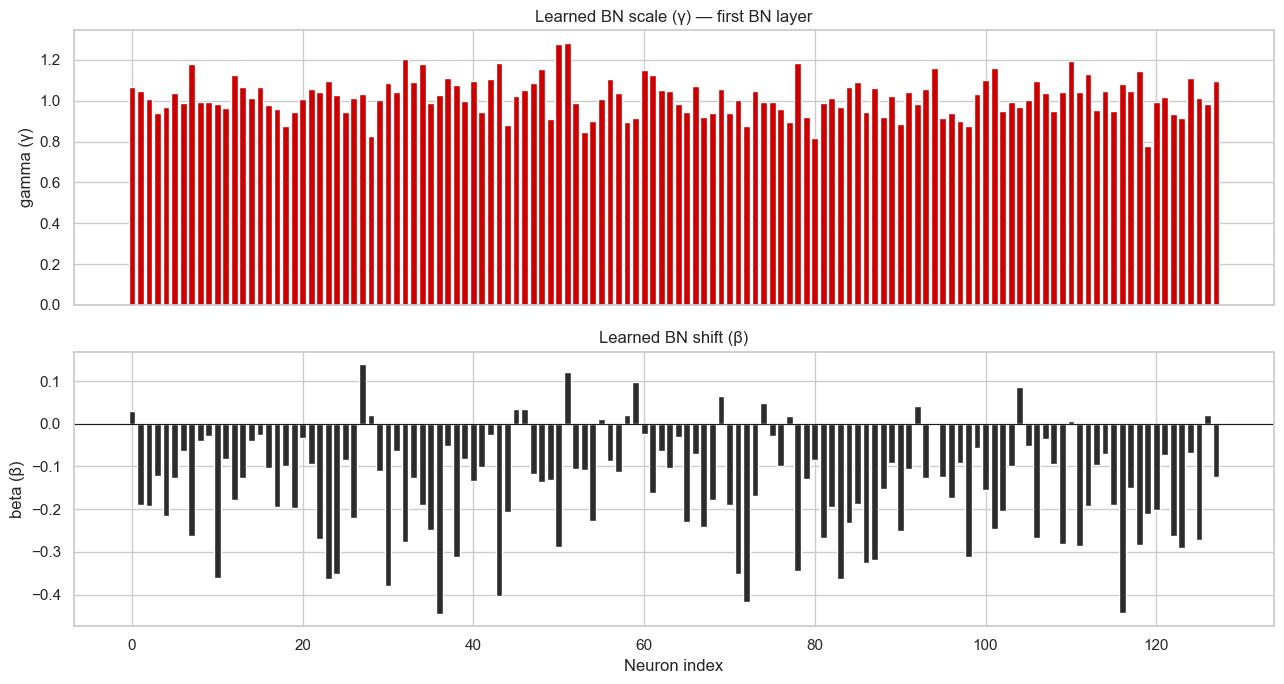

**0 of 128 neurons** have |γ| < 0.128 (10% of the largest |γ|); strongest neurons: [51, 50, 32, 110, 78] (|γ| = [1.2799999713897705, 1.2799999713897705, 1.2100000381469727, 1.2000000476837158, 1.190000057220459]).

In [33]:
bn_layer = model_bn.layers[1]                      
gamma, beta, running_mean, running_var = bn_layer.get_weights()
print(bn_layer.name, '| gamma', gamma.shape, '| beta', beta.shape)

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].bar(range(len(gamma)), gamma, color=RED);      ax[0].axhline(0, color='k', lw=.8); ax[0].set_ylabel('gamma (γ)'); ax[0].set_title('Learned BN scale (γ) — first BN layer')
ax[1].bar(range(len(beta)),  beta,  color=CHARCOAL); ax[1].axhline(0, color='k', lw=.8); ax[1].set_ylabel('beta (β)');  ax[1].set_title('Learned BN shift (β)'); ax[1].set_xlabel('Neuron index')
plt.tight_layout(); plt.show()

thr = 0.1 * np.abs(gamma).max()
small = int(np.sum(np.abs(gamma) < thr))
top = np.argsort(-np.abs(gamma))[:5]
display(Markdown(f"**{small} of {len(gamma)} neurons** have |γ| < {thr:.3f} (10% of the largest |γ|); strongest neurons: {top.tolist()} (|γ| = {np.round(np.abs(gamma[top]), 2).tolist()})."))

In [34]:
opt_factories = {
 '(a) sgd':               lambda: 'sgd',
 '(b) sgd+momentum':      lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
 '(c) rmsprop':           lambda: 'rmsprop',
 '(d) adam':              lambda: 'adam',
 '(e) adam (explicit)':   lambda: keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999),
}
models_opt, hist_opt = {}, {}
for name, fac in opt_factories.items():
    print('Training optimiser', name)
    m = build_ann(input_dim=X_train.shape[1], activation='relu', initializer='he_normal',
                  use_batch_norm=True, optimizer=fac(), loss='binary_crossentropy')
    hist_opt[name] = fit_model(m, epochs=EPOCHS)
    models_opt[name] = m
    record(f'Opt: {name}', m, init='he_normal', bn=True, opt=name.split(') ')[1])
pd.DataFrame([all_results[f'Opt: {n}'] for n in opt_factories])[['Model','Test Acc','Prec(1)','Recall(1)','F1(1)','ROC-AUC']]

Training optimiser (a) sgd
Training optimiser (b) sgd+momentum
Training optimiser (c) rmsprop
Training optimiser (d) adam
Training optimiser (e) adam (explicit)


,Model,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Opt: (a) sgd,0.853068,0.735674,0.635593,0.681981,0.908393
1,Opt: (b) sgd+momentum,0.823881,0.652133,0.620428,0.635886,0.881289
2,Opt: (c) rmsprop,0.827087,0.670523,0.594558,0.630260,0.875396
3,Opt: (d) adam,0.813599,0.658676,0.514719,0.577867,0.870336
4,Opt: (e) adam (explicit),0.813599,0.658676,0.514719,0.577867,0.870336


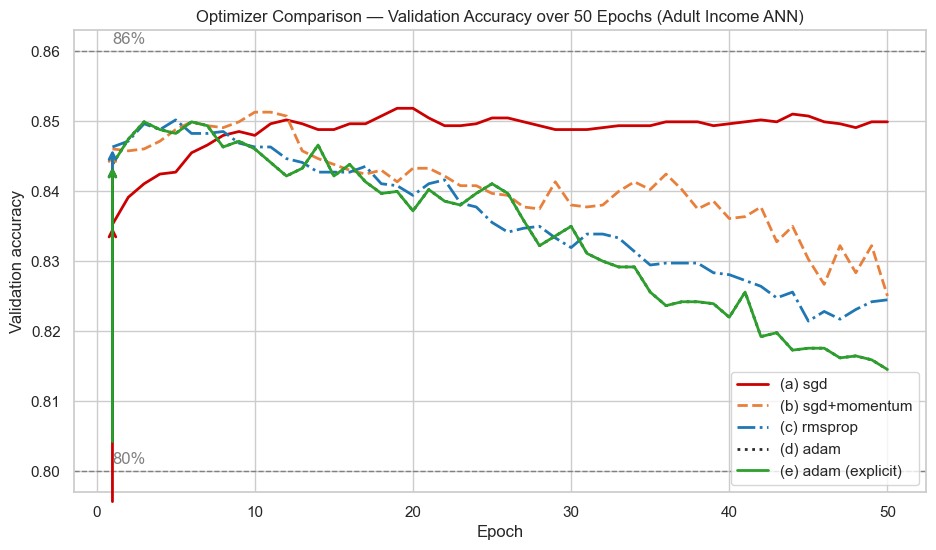

(a) sgd                first epoch >= 83%: 1
(b) sgd+momentum       first epoch >= 83%: 1
(c) rmsprop            first epoch >= 83%: 1
(d) adam               first epoch >= 83%: 1
(e) adam (explicit)    first epoch >= 83%: 1


In [35]:
cols = [RED, '#E8803C', '#1F77B4', CHARCOAL, '#2CA02C']
ls   = ['-', '--', '-.', ':', '-']
plt.figure(figsize=(11, 6))
for (name, h), c, l in zip(hist_opt.items(), cols, ls):
    va = h.history['val_accuracy']; ep = np.arange(1, len(va) + 1)
    plt.plot(ep, va, color=c, ls=l, lw=2, label=name)
    e = first_cross(va, 0.83)
    if e is not None:
        plt.annotate('', xy=(e + 1, va[e]), xytext=(e + 1, va[e] - 0.04),
                     arrowprops=dict(arrowstyle='->', color=c, lw=2))     
for y_ref in (0.80, 0.86):
    plt.axhline(y_ref, color='gray', ls='--', lw=1)
    plt.text(1, y_ref + 0.001, f'{int(y_ref*100)}%', color='gray')
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy'); plt.legend(loc='lower right')
plt.title('Optimizer Comparison — Validation Accuracy over 50 Epochs (Adult Income ANN)')
plt.show()
for name, h in hist_opt.items():
    e = first_cross(h.history['val_accuracy'], 0.83)
    print(f'{name:22s} first epoch >= 83%:', 'never' if e is None else e + 1)

In [36]:
opt_f1 = {n: all_results[f'Opt: {n}']['F1(1)'] for n in opt_factories}
fastest = {n: first_cross(h.history['val_accuracy'], 0.83) for n, h in hist_opt.items()}
fastest = {n: (e if e is not None else 10**9) for n, e in fastest.items()}
best_f1_opt, fastest_opt = max(opt_f1, key=opt_f1.get), min(fastest, key=fastest.get)
display(Markdown(f"**Highest final class-1 F1:** {best_f1_opt} ({opt_f1[best_f1_opt]:.3f}).  "
                 f"**Converged fastest (first epoch ≥ 83% val acc):** {fastest_opt} "
                 f"({'epoch ' + str(fastest[fastest_opt] + 1) if fastest[fastest_opt] < 10**9 else 'none reached 83%'})."))

**Highest final class-1 F1:** (a) sgd (0.682).  **Converged fastest (first epoch ≥ 83% val acc):** (a) sgd (epoch 1).

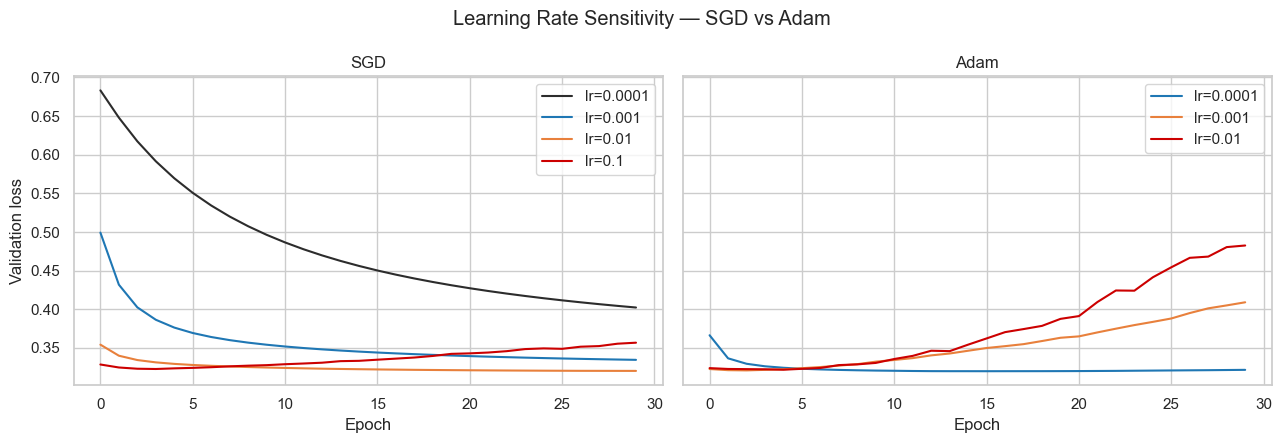

In [37]:
sgd_lrs, adam_lrs = [0.0001, 0.001, 0.01, 0.1], [0.0001, 0.001, 0.01]
def lr_run(opt_cls, lr):
    m = build_ann(input_dim=D, activation='relu', initializer='he_normal', use_batch_norm=True,
                  optimizer=opt_cls(learning_rate=lr), loss='binary_crossentropy')
    return fit_model(m, epochs=EPOCHS_SHORT).history['val_loss']

lr_sgd  = {lr: lr_run(keras.optimizers.SGD,  lr) for lr in sgd_lrs}
lr_adam = {lr: lr_run(keras.optimizers.Adam, lr) for lr in adam_lrs}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for lr, c in zip(sgd_lrs, [CHARCOAL, '#1F77B4', '#E8803C', RED]):  ax[0].plot(lr_sgd[lr],  color=c, label=f'lr={lr}')
for lr, c in zip(adam_lrs, ['#1F77B4', '#E8803C', RED]):            ax[1].plot(lr_adam[lr], color=c, label=f'lr={lr}')
ax[0].set_title('SGD'); ax[1].set_title('Adam')
for a in ax: a.set_xlabel('Epoch'); a.legend()
ax[0].set_ylabel('Validation loss')
fig.suptitle('Learning Rate Sensitivity — SGD vs Adam'); plt.tight_layout(); plt.show()

Weighted BCE improved F1 over baseline -> True
{'Test Acc': 0.8157, 'Prec(1)': 0.6306, 'Recall(1)': 0.6191, 'F1(1)': 0.6248, 'ROC-AUC': 0.8713}


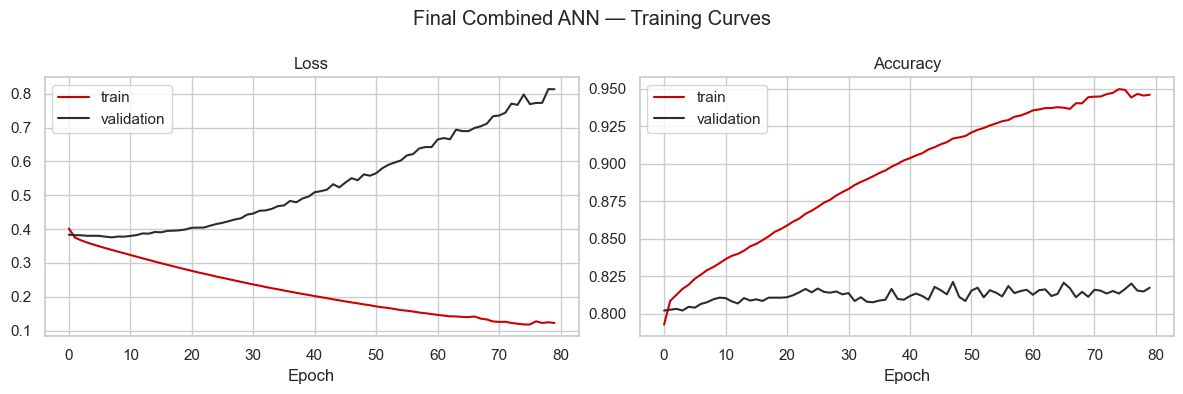

In [38]:
use_wbce = all_results['Weighted BCE']['F1(1)'] > all_results['Baseline']['F1(1)']
print('Weighted BCE improved F1 over baseline ->', use_wbce)

model_final = build_ann(input_dim=X_train.shape[1], hidden_units=[128, 64], activation='relu',
                        initializer='he_normal', use_batch_norm=True, optimizer='adam',
                        loss='binary_crossentropy')
history_final = fit_model(model_final, epochs=EPOCHS_FINAL, class_weight=class_weight_dict if use_wbce else None)
row = record('Final Combined', model_final, init='he_normal', loss='Weighted BCE' if use_wbce else 'BCE', bn=True)
print({k: round(v, 4) for k, v in row.items() if k in ['Test Acc', 'Prec(1)', 'Recall(1)', 'F1(1)', 'ROC-AUC']})
plot_curves(history_final, 'Final Combined ANN — Training Curves')

,Model,Activation,Init,Loss,BatchNorm,Optimizer,Test Acc,Prec(1),Recall(1),F1(1),ROC-AUC
0,Baseline (Task 2),relu,glorot_uniform,BCE,False,adam,0.8364,0.7016,0.5914,0.6418,0.8873
1,Best Activation: sigmoid (Task 3),sigmoid,glorot_uniform,BCE,False,adam,0.8531,0.7501,0.6106,0.6732,0.9119
2,Best Initialiser: glorot_uniform (Task 4),relu,glorot_uniform,BCE,False,adam,0.8364,0.7016,0.5914,0.6418,0.8873
3,Weighted BCE (Task 5),relu,he_normal,Weighted BCE,False,adam,0.7981,0.5664,0.7917,0.6603,0.8824
4,Focal Loss (Task 5),relu,he_normal,Focal,False,adam,0.8207,0.7897,0.3769,0.5103,0.8790
5,BatchNorm model (Task 6),relu,he_normal,BCE,True,adam,0.8136,0.6587,0.5147,0.5779,0.8703
6,Final Combined (Task 7),relu,he_normal,Weighted BCE,True,adam,0.8157,0.6306,0.6191,0.6248,0.8713


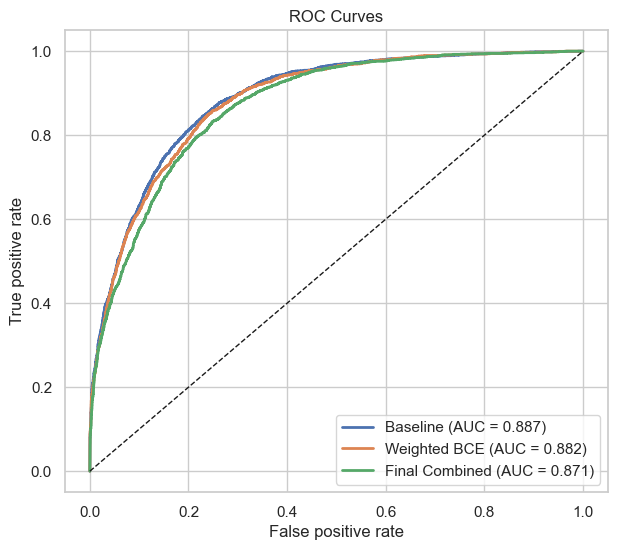

In [39]:
best_a = max(acts,  key=lambda a: all_results[f'Act: {a}']['F1(1)'])
best_i = max(inits, key=lambda i: all_results[f'Init: {i}']['F1(1)'])
rows = [all_results['Baseline'], all_results[f'Act: {best_a}'], all_results[f'Init: {best_i}'],
        all_results['Weighted BCE'], all_results['Focal Loss'], all_results['BatchNorm'], all_results['Final Combined']]
labels = ['Baseline (Task 2)', f'Best Activation: {best_a} (Task 3)', f'Best Initialiser: {best_i} (Task 4)',
          'Weighted BCE (Task 5)', 'Focal Loss (Task 5)', 'BatchNorm model (Task 6)', 'Final Combined (Task 7)']
results_df = pd.DataFrame(rows).reset_index(drop=True)
results_df['Model'] = labels
results_df = results_df[['Model', 'Activation', 'Init', 'Loss', 'BatchNorm', 'Optimizer',
                         'Test Acc', 'Prec(1)', 'Recall(1)', 'F1(1)', 'ROC-AUC']]
display(results_df.style.highlight_max(subset=['F1(1)', 'ROC-AUC'], color='#ffcccc')
        .format({c: '{:.4f}' for c in ['Test Acc', 'Prec(1)', 'Recall(1)', 'F1(1)', 'ROC-AUC']}))

plt.figure(figsize=(7, 6))
for n in ['Baseline', 'Weighted BCE', 'Final Combined']:
    prob = trained[n].predict(X_test, verbose=0).ravel()
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC = {all_results[n]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('ROC Curves'); plt.legend(); plt.show()

In [40]:
base_f1 = all_results['Baseline']['F1(1)']
opt_best = max((n for n in all_results if n.startswith('Opt:')), key=lambda n: all_results[n]['F1(1)'])
deltas = {
  'Activation':            all_results[f'Act: {best_a}']['F1(1)'] - base_f1,
  'Initialiser':           all_results[f'Init: {best_i}']['F1(1)'] - base_f1,
  'Loss (weighted BCE)':   all_results['Weighted BCE']['F1(1)'] - base_f1,
  'Loss (focal)':          all_results['Focal Loss']['F1(1)'] - base_f1,
  'Batch Normalisation':   all_results['BatchNorm']['F1(1)'] - base_f1,
  'Optimiser':             all_results[opt_best]['F1(1)'] - base_f1,
}
why = {
 'Activation': 'the activation changes the non-linearity and gradient flow of every hidden layer; ReLU-family units avoid saturation.',
 'Initialiser': 'a good starting point (He for ReLU) keeps activations/gradients well scaled and breaks symmetry, speeding up and stabilising learning.',
 'Loss (weighted BCE)': 'it directly changes the objective: errors on the 25% minority class are weighted ~2x, shifting the decision boundary and raising recall — which is exactly what F1 of the minority class rewards.',
 'Loss (focal)': 'it re-weights examples by difficulty, concentrating learning on hard minority-class samples.',
 'Batch Normalisation': 'it stabilises the scale of layer inputs, allowing faster, more reliable optimisation.',
 'Optimiser': 'adaptive optimisers converge to a better solution within the epoch budget than plain SGD.',
}
print(pd.Series(deltas).sort_values(ascending=False).round(4).to_string())
top = max(deltas, key=deltas.get)
display(Markdown(f"**Largest individual impact on minority-class F1: {top}** (ΔF1 = {deltas[top]:+.3f} vs the Task 2 baseline). Why: {why[top]}  \n"
                 "*Caveat: all deltas are single runs measured against the baseline (the optimiser/BN rows also include He-init + BN), so differences of ~0.01 are within run-to-run noise.*"))

Optimiser              0.0402
Activation             0.0314
Loss (weighted BCE)    0.0185
Initialiser            0.0000
Batch Normalisation   -0.0640
Loss (focal)          -0.1316


**Largest individual impact on minority-class F1: Optimiser** (ΔF1 = +0.040 vs the Task 2 baseline). Why: adaptive optimisers converge to a better solution within the epoch budget than plain SGD.  
*Caveat: all deltas are single runs measured against the baseline (the optimiser/BN rows also include He-init + BN), so differences of ~0.01 are within run-to-run noise.*

---
### Wrap-up
* **Imbalance matters most for F1 on the minority class** — compare the loss/weighting experiments with the architecture-level changes in the table above.
* **Initialisation, activation and optimiser** mainly affect *how quickly and reliably* the network trains; zero-init and a badly tuned SGD show clearly what goes wrong.
* **Batch Normalisation** gives smoother, faster training; its benefit on a shallow tabular MLP is real but modest.
* For production: ReLU + He-normal + BatchNorm + Adam, with weighted BCE (or a tuned decision threshold) when recall on `>50K` matters.